In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats


## Задание 1

* H0: среднее время равно 120 с (mu = 120)
* H1: среднее время не равно 120 с (mu != 120)


SE: 2.5 сек
z: 1.60 стандартных ошибок
Критический интервал: от -1.96 до 1.96
p-value: 0.1096
p-value 0.1096 > 0.05: нет оснований отвергать H0, разница статистически незначима


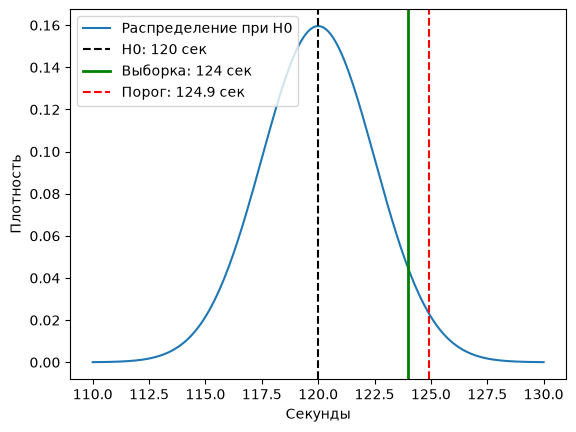

In [2]:
# входные данные
mu_0 = 120
x_bar = 124
sigma = 25
n = 100
alpha = 0.05

# стандартная ошибка среднего
se = sigma / np.sqrt(n)

# z-статистика
z = (x_bar - mu_0) / se

# p-value и критический порог
p_val = 2 * (1 - stats.norm.cdf(abs(z)))
crit_z = stats.norm.ppf(1 - alpha / 2)

print(f"SE: {se} сек")
print(f"z: {z:.2f} стандартных ошибок")
print(f"Критический интервал: от -{crit_z:.2f} до {crit_z:.2f}")
print(f"p-value: {p_val:.4f}")

if abs(z) > crit_z:
    print(f"p-value {p_val:.4f} <= {alpha}: отвергаем H0, разница статистически значима")
else:
    print(f"p-value {p_val:.4f} > {alpha}: нет оснований отвергать H0, разница статистически незначима")

# простой график
x = np.linspace(110, 130, 200)
y = stats.norm.pdf(x, mu_0, se)

plt.plot(x, y, label="Распределение при H0")
plt.axvline(mu_0, color="black", linestyle="--", label=f"H0: {mu_0} сек")
plt.axvline(x_bar, color="green", linewidth=2, label=f"Выборка: {x_bar} сек")
plt.axvline(mu_0 + crit_z * se, color="red", linestyle="--", label=f"Порог: {mu_0 + crit_z * se:.1f} сек")
plt.xlabel("Секунды")
plt.ylabel("Плотность")
plt.legend()
plt.show()


## Задание 2

* H0: средние в группах равны (mu1 = mu2)
* H1: средние в группах различаются (mu1 != mu2)


Разница средних: 5
SE: 2.2361
df: 78.0
95% доверительный интервал: [0.55, 9.45]
0 не попадает в интервал: H0 отвергается, эффект значим
Самый маленький эффект, согласующийся с данными: 0.55


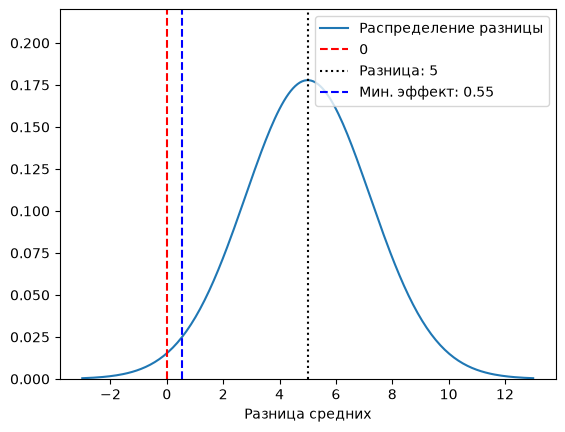

In [3]:
# входные данные
n1, x1, s1 = 40, 50, 10
n2, x2, s2 = 40, 55, 10
alpha = 0.05

# разница средних
diff = x2 - x1

# стандартная ошибка разности
se = np.sqrt(s1**2 / n1 + s2**2 / n2)

# степени свободы Уэлча
df = (s1**2 / n1 + s2**2 / n2)**2 / ((s1**2 / n1)**2 / (n1 - 1) + (s2**2 / n2)**2 / (n2 - 1))

# 95% доверительный интервал
t_crit = stats.t.ppf(1 - alpha / 2, df)
ci_low = diff - t_crit * se
ci_high = diff + t_crit * se

print(f"Разница средних: {diff}")
print(f"SE: {se:.4f}")
print(f"df: {df:.1f}")
print(f"95% доверительный интервал: [{ci_low:.2f}, {ci_high:.2f}]")

if ci_low <= 0 <= ci_high:
    print("0 попадает в интервал: H0 не отвергается")
else:
    print("0 не попадает в интервал: H0 отвергается, эффект значим")

print(f"Самый маленький эффект, согласующийся с данными: {ci_low:.2f}")

# компактный график распределения разницы
x = np.linspace(-3, 13, 200)
plt.plot(x, stats.t.pdf(x, df=df, loc=diff, scale=se), label="Распределение разницы")
plt.axvline(0, color="red", linestyle="--", label="0")
plt.axvline(diff, color="black", linestyle=":", label=f"Разница: {diff}")
plt.axvline(ci_low, color="blue", linestyle="--", label=f"Мин. эффект: {ci_low:.2f}")
plt.xlabel("Разница средних")
plt.ylim(0, 0.22)
plt.legend(loc="upper right")
plt.show()


## Задание 3

* H0: конверсии равны (p1 = p2)
* H1: конверсии различаются (p1 != p2)


In [4]:
# входные данные
x1, n1 = 90, 1000
x2, n2 = 120, 1000
alpha = 0.05

# конверсии
p1 = x1 / n1
p2 = x2 / n2
diff_pp = (p2 - p1) * 100

# объединенная доля и стандартная ошибка
p_pool = (x1 + x2) / (n1 + n2)
se = np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))

# z-статистика и p-value
z = (p2 - p1) / se
p_val = 2 * (1 - stats.norm.cdf(abs(z)))
crit_z = stats.norm.ppf(1 - alpha / 2)

print(f"Конверсия 1: {p1 * 100:.1f}%")
print(f"Конверсия 2: {p2 * 100:.1f}%")
print(f"Разница: {diff_pp:.1f} п.п.")
print(f"z-статистика: {z:.2f}")
print(f"p-value: {p_val:.4f}")

if abs(z) > crit_z:
    print(f"p-value {p_val:.4f} <= {alpha}: отвергаем H0, разница значима")
else:
    print(f"p-value {p_val:.4f} > {alpha}: нет оснований отвергать H0, разница незначима")


Конверсия 1: 9.0%
Конверсия 2: 12.0%
Разница: 3.0 п.п.
z-статистика: 2.19
p-value: 0.0287
p-value 0.0287 <= 0.05: отвергаем H0, разница значима


## Задание 4

* H0: распределения в обеих группах одинаковые
* H1: распределения различаются


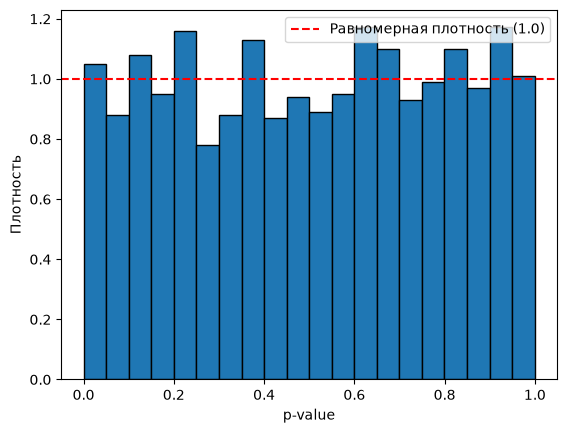

Доля p-value < 0.05: 0.051


In [ ]:
rng = np.random.default_rng(42)

n_sims = 2000
n = 200

p_values = []

for _ in range(n_sims):
    group1 = rng.normal(0, 1, n)
    group2 = rng.normal(0, 1, n)
    res = stats.ttest_ind(group1, group2, equal_var=False)
    p_values.append(res.pvalue)

p_values = np.array(p_values)

plt.hist(p_values, bins=20, edgecolor="black", density=True)
plt.axhline(1.0, color="red", linestyle="--", label="Равномерная плотность")
plt.xlabel("p-value")
plt.ylabel("Плотность")
plt.legend()
plt.show()

print(f"Доля p-value < 0.05: {(p_values < 0.05).mean():.3f}")


Распределение получилось равномерным, все столбики идут примерно на одном уровне от нуля до единицы. Разницы между группами изначально нет, поэтому любое значение p-value выпадает одинаково часто. Тест находит ложные отличия при пороге 0.05 ровно в пяти процентах экспериментов, как и заложено в теории.


## Задание 5

* H0: распределения в группах одинаковые
* H1: распределения различаются


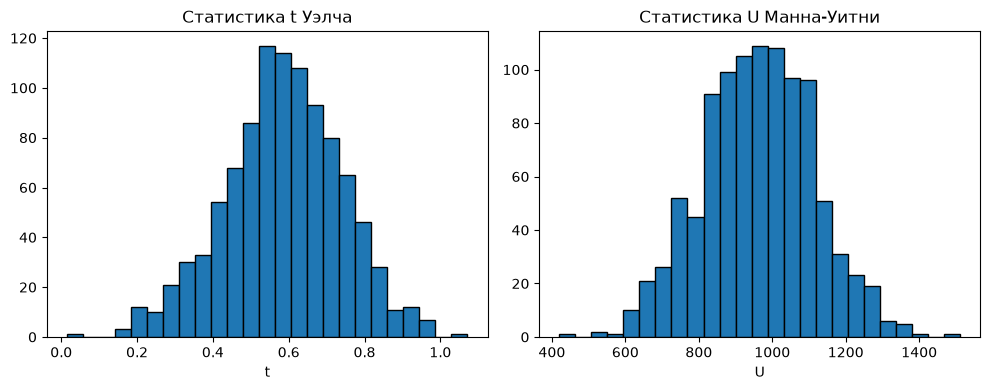

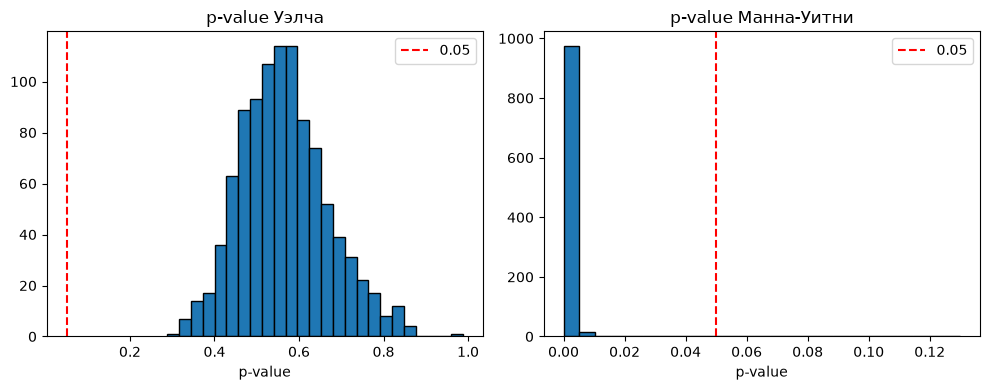

Доля p-value < 0.05 у критерия Уэлча: 0.000
Доля p-value < 0.05 у Манна-Уитни: 0.999


In [6]:
rng = np.random.default_rng(42)

n_sims = 1000
n = 60

diffs = []
t_stats = []
t_pvals = []
u_stats = []
u_pvals = []

for _ in range(n_sims):
    group1 = rng.normal(0, 1, n)
    group2 = rng.normal(1, 1, n)
    group2[0] = -50
    group2[1] = -50

    diffs.append(group2.mean() - group1.mean())

    res_t = stats.ttest_ind(group1, group2, equal_var=False)
    t_stats.append(res_t.statistic)
    t_pvals.append(res_t.pvalue)

    res_u = stats.mannwhitneyu(group1, group2, alternative="two-sided")
    u_stats.append(res_u.statistic)
    u_pvals.append(res_u.pvalue)

t_stats = np.array(t_stats)
u_stats = np.array(u_stats)
t_pvals = np.array(t_pvals)
u_pvals = np.array(u_pvals)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.hist(t_stats, bins=25, edgecolor="black")
plt.title("Статистика t Уэлча")
plt.xlabel("t")

plt.subplot(1, 2, 2)
plt.hist(u_stats, bins=25, edgecolor="black")
plt.title("Статистика U Манна-Уитни")
plt.xlabel("U")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.hist(t_pvals, bins=25, edgecolor="black")
plt.axvline(0.05, color="red", linestyle="--", label="0.05")
plt.title("p-value Уэлча")
plt.xlabel("p-value")
plt.legend()

plt.subplot(1, 2, 2)
plt.hist(u_pvals, bins=25, edgecolor="black")
plt.axvline(0.05, color="red", linestyle="--", label="0.05")
plt.title("p-value Манна-Уитни")
plt.xlabel("p-value")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Доля p-value < 0.05 у критерия Уэлча: {(t_pvals < 0.05).mean():.3f}")
print(f"Доля p-value < 0.05 у Манна-Уитни: {(u_pvals < 0.05).mean():.3f}")


Критерий Уэлча ни разу не отклонил нулевую гипотезу при пороге 0.05, его p-value всегда получились большими и сосредоточены в районе 0.7 - 0.9. Критерий Манна-Уитни отклонил нулевую гипотезу почти в ста процентах случаев, его p-value лежат около нуля. 

Выводы разошлись из-за двух сильных выбросов по минус пятьдесят. Среднее значение и дисперсия во второй группе сломались, из-за чего раздулась стандартная ошибка и t-тест перестал видеть разницу. Манн-Уитни работает по рангам, поэтому двум выбросам он просто дал первые места и спокойно зафиксировал сдвиг остальных пятидесяти восьми элементов.


## Задание 6

* H0: средние в группах равны (mu2 - mu1 = 0)
* H1: средние в группах различаются (mu2 - mu1 != 0)


In [7]:
rng = np.random.default_rng(42)

group1 = rng.normal(10, 2, 80)
group2 = rng.normal(10.8, 2.6, 75)

res = stats.ttest_ind(group2, group1, equal_var=False)
ci = res.confidence_interval(confidence_level=0.95)
diff = group2.mean() - group1.mean()

print(f"Разница средних: {diff:.4f}")
print(f"p-value: {res.pvalue:.4f}")
print(f"95% доверительный интервал: [{ci.low:.4f}, {ci.high:.4f}]")

if ci.low <= 0 <= ci.high:
    print("0 попадает в доверительный интервал")
else:
    print("0 не попадает в доверительный интервал")

if res.pvalue > 0.05:
    print("p-value > 0.05: нет оснований отвергать H0, разница незначима")
else:
    print("p-value <= 0.05: отвергаем H0, разница значима")

print(f"Самый маленький эффект, согласующийся с данными: {ci.low:.4f}")


Разница средних: 0.2960
p-value: 0.3692
95% доверительный интервал: [-0.3540, 0.9460]
0 попадает в доверительный интервал
p-value > 0.05: нет оснований отвергать H0, разница незначима
Самый маленький эффект, согласующийся с данными: -0.3540


Ноль попадает в 95% доверительный интервал, а p-value больше 0.05. Оснований отвергать H0 нет, разница незначима. Самый маленький эффект, который еще согласуется с данными: -0.3540.


## Задание 7

* H0: средние в группах равны (mu2 - mu1 = 0)
* H1: средние в группах различаются (mu2 - mu1 != 0)


95% интервал бутстрапа: [-0.3157, 0.9201]
Доля разниц <= 0: 0.1635


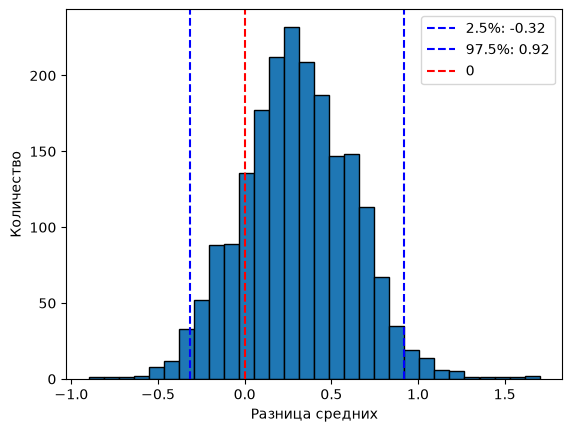

In [8]:
n_boot = 2000
boot_diffs = []

for _ in range(n_boot):
    b1 = rng.choice(group1, size=len(group1), replace=True)
    b2 = rng.choice(group2, size=len(group2), replace=True)
    boot_diffs.append(b2.mean() - b1.mean())

boot_diffs = np.array(boot_diffs)

ci_boot = np.percentile(boot_diffs, [2.5, 97.5])
frac_le_zero = (boot_diffs <= 0).mean()

print(f"95% интервал бутстрапа: [{ci_boot[0]:.4f}, {ci_boot[1]:.4f}]")
print(f"Доля разниц <= 0: {frac_le_zero:.4f}")

plt.hist(boot_diffs, bins=30, edgecolor="black")
plt.axvline(ci_boot[0], color="blue", linestyle="--", label=f"2.5%: {ci_boot[0]:.2f}")
plt.axvline(ci_boot[1], color="blue", linestyle="--", label=f"97.5%: {ci_boot[1]:.2f}")
plt.axvline(0, color="red", linestyle="--", label="0")
plt.xlabel("Разница средних")
plt.ylabel("Количество")
plt.legend()
plt.show()


Границы бутстрапа от -0.3157 до 0.9201 получились практически такими же, как границы интервала из предыдущего задания от -0.3540 до 0.9460.

Долю разниц меньше или равных нулю 16.35% нельзя назвать p-value. Бутстрап строился вокруг нашей выборочной разницы 0.296, а не вокруг нуля. Для настоящего p-value нужно проверять гипотезу строго при условии, что разница равна нулю.
